#  Finance-Instruct-500k — Data Cleaning, Audit & Analysis Pipeline


---
##  Step 1: Mount Google Drive & Locate Dataset


In [1]:
from google.colab import drive
import os
import sys
import json
import zipfile
import re
import time
import pandas as pd
import numpy as np

# Mount Google Drive
drive.mount('/content/drive')

DRIVE_PROJECT_DIR = '/content/drive/MyDrive/google_colab_project'

# Auto-detect folder location if placed in another directory in Drive
DATASET_FILE = None
search_roots = ['/content/drive/MyDrive', '/content']

for sroot in search_roots:
    if os.path.exists(sroot):
        for root, dirs, files in os.walk(sroot):
            for f in files:
                if 'finance-instruct' in f.lower() or f == 'train.json':
                    DATASET_FILE = os.path.join(root, f)
                    print(f"✅ Found dataset at: {DATASET_FILE}")
                    break
            if DATASET_FILE:
                break
    if DATASET_FILE:
        break

if not DATASET_FILE:
    print("⚠️ Dataset not automatically found. Please set DATASET_FILE path manually.")
    DATASET_FILE = '/content/drive/MyDrive/google_colab_project/Finance-Instruct-500k/train.json'
else:
    print(f"Working target: {DATASET_FILE}")


Mounted at /content/drive
✅ Found dataset at: /content/drive/MyDrive/google_colab_project/train.json
Working target: /content/drive/MyDrive/google_colab_project/train.json


---
##  2: Configure Environment & Plot Styling


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✅ Visualization styling initialized!")


✅ Visualization styling initialized!


---
##  3: Fast Quality Audit (Streaming Scan)


In [3]:
# Fast streaming audit over first 50,000 records
def audit_sample(filepath, max_records=50000):
    empty_users = 0
    empty_assts = 0
    empty_systems = 0
    user_words = []
    asst_words = []

    # Handle both raw jsonl/json and zip files
    open_fn = lambda p: zipfile.ZipFile(p).open('Finance-Instruct-500k/train.json') if p.endswith('.zip') else open(p, 'rb')

    with open_fn(filepath) as f:
        for idx, line in enumerate(f):
            if idx >= max_records:
                break
            try:
                rec = json.loads(line.decode('utf-8', errors='replace'))
                u = rec.get('user', '').strip()
                a = rec.get('assistant', '').strip()
                s = rec.get('system', '').strip()

                if not u: empty_users += 1
                if not a: empty_assts += 1
                if not s: empty_systems += 1

                user_words.append(len(u.split()))
                asst_words.append(len(a.split()))
            except Exception:
                continue

    print(f"=== AUDIT RESULTS (Sample: {len(user_words):,} records) ===")
    print(f"• Empty User Prompts: {empty_users}")
    print(f"• Empty Assistant Responses: {empty_assts}")
    print(f"• Missing/Blank System Prompts: {empty_systems} ({empty_systems/len(user_words)*100:.1f}%)")
    print(f"• Average User Word Count: {np.mean(user_words):.1f}")
    print(f"• Average Assistant Word Count: {np.mean(asst_words):.1f}")

if os.path.exists(DATASET_FILE):
    audit_sample(DATASET_FILE, max_records=50000)


=== AUDIT RESULTS (Sample: 50,000 records) ===
• Empty User Prompts: 0
• Empty Assistant Responses: 0
• Missing/Blank System Prompts: 50000 (100.0%)
• Average User Word Count: 84.9
• Average Assistant Word Count: 248.0


---
##  4: Cleaning & Financial Categorization Pipeline


In [4]:
def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.replace('\xa0', ' ').replace('\u200b', '').replace('\ufeff', '')
    text = re.sub(r'[ \t]+', ' ', text)
    return text.strip()

def detect_category(user_text: str, assistant_text: str) -> str:
    combined = (user_text + " " + assistant_text).lower()
    if any(k in combined for k in ['inflation', 'gdp', 'interest rate', 'central bank', 'monetary policy', 'fiscal policy', 'macroeconomic', 'unemployment rate', 'federal reserve']):
        return 'Macroeconomics & Monetary Policy'
    elif any(k in combined for k in ['stock', 'equity', 'dividend', 'nasdaq', 's&p', 'portfolio', 'bond', 'yield', 'etf', 'option', 'hedge fund', 'trading']):
        return 'Investments & Financial Markets'
    elif any(k in combined for k in ['balance sheet', 'ebitda', 'cash flow', 'depreciation', 'revenue', 'valuation', 'merger', 'acquisition', 'audit', 'p&l']):
        return 'Corporate Finance & Accounting'
    elif any(k in combined for k in ['crypto', 'bitcoin', 'blockchain', 'ethereum', 'fintech', 'defi', 'digital currency']):
        return 'Crypto & FinTech'
    elif any(k in combined for k in ['tax', 'regulation', 'sec', 'compliance', 'irs', 'legal', 'anti-money laundering', 'kyc', 'pii']):
        return 'Regulation, Tax & Compliance'
    elif any(k in combined for k in ['budget', 'savings', 'credit card', 'mortgage', 'loan', 'debt', 'personal finance', 'retirement', '401k']):
        return 'Personal Finance & Banking'
    else:
        return 'General Financial Advisory'

print("✅ Pipeline helper functions defined!")


✅ Pipeline helper functions defined!


---
## 5: Execute Streaming Cleaning Pipeline


In [5]:
output_dir = '/content/drive/MyDrive/google_colab_project'
os.makedirs(output_dir, exist_ok=True)

CLEANED_JSONL_PATH = os.path.join(output_dir, 'finance_instruct_500k_cleaned.jsonl')
SAMPLE_CSV_PATH = os.path.join(output_dir, 'finance_instruct_500k_sample_cleaned.csv')

def process_and_clean(input_path, output_jsonl, output_csv, max_sample_rows=30000, process_limit=None):
    open_fn = lambda p: zipfile.ZipFile(p).open('Finance-Instruct-500k/train.json') if p.endswith('.zip') else open(p, 'rb')

    seen_prompts = set()
    cleaned_count = 0
    sample_records = []
    start_time = time.time()

    with open_fn(input_path) as infile, open(output_jsonl, 'w', encoding='utf-8') as outfile:
        for idx, line in enumerate(infile):
            if process_limit and idx >= process_limit:
                break

            try:
                rec = json.loads(line.decode('utf-8', errors='replace'))
            except Exception:
                continue

            user = clean_text(rec.get('user', ''))
            assistant = clean_text(rec.get('assistant', ''))
            system = clean_text(rec.get('system', ''))

            if not system:
                system = "You are a knowledgeable and accurate financial AI assistant."

            # Quality filters
            if len(user) < 3 or len(assistant) < 3:
                continue

            user_hash = hash(user)
            if user_hash in seen_prompts:
                continue
            seen_prompts.add(user_hash)

            cleaned_count += 1
            user_words = len(user.split())
            asst_words = len(assistant.split())

            clean_row = {
                'id': cleaned_count,
                'system': system,
                'user': user,
                'assistant': assistant
            }
            outfile.write(json.dumps(clean_row, ensure_ascii=False) + '\n')

            if cleaned_count <= max_sample_rows:
                cat = detect_category(user, assistant)
                has_code = 1 if '```' in assistant or any(s in assistant for s in ['∑', '∫', 'sqrt(', '=']) else 0
                sample_records.append({
                    'id': cleaned_count,
                    'category': cat,
                    'user_prompt': user,
                    'assistant_response': assistant,
                    'system_prompt': system,
                    'user_word_count': user_words,
                    'assistant_word_count': asst_words,
                    'response_to_prompt_ratio': round(asst_words / max(1, user_words), 2),
                    'has_calculation_or_code': has_code
                })

            if (idx + 1) % 50000 == 0:
                print(f"Processed {idx + 1:,} rows ({cleaned_count:,} valid) in {time.time() - start_time:.1f}s...")

    df_sample = pd.DataFrame(sample_records)
    df_sample.to_csv(output_csv, index=False, encoding='utf-8')
    print(f"\n✅ Cleaned dataset saved to: {output_jsonl}")
    print(f"✅ Cleaned sample CSV saved to: {output_csv}")
    return df_sample

df_sample = process_and_clean(DATASET_FILE, CLEANED_JSONL_PATH, SAMPLE_CSV_PATH, max_sample_rows=30000)
display(df_sample.head(3))


Processed 100,000 rows (65,895 valid) in 31.6s...
Processed 150,000 rows (115,459 valid) in 35.0s...
Processed 200,000 rows (157,396 valid) in 39.9s...
Processed 250,000 rows (204,844 valid) in 43.6s...
Processed 300,000 rows (249,766 valid) in 46.2s...
Processed 350,000 rows (299,466 valid) in 52.9s...
Processed 400,000 rows (335,244 valid) in 59.4s...
Processed 450,000 rows (385,187 valid) in 66.0s...
Processed 500,000 rows (434,583 valid) in 72.0s...

✅ Cleaned dataset saved to: /content/drive/MyDrive/google_colab_project/finance_instruct_500k_cleaned.jsonl
✅ Cleaned sample CSV saved to: /content/drive/MyDrive/google_colab_project/finance_instruct_500k_sample_cleaned.csv


,id,category,user_prompt,assistant_response,system_prompt,user_word_count,assistant_word_count,response_to_prompt_ratio,has_calculation_or_code
0,1,Macroeconomics & Monetary Policy,Explain tradeoffs between fiscal and monetary ...,Fiscal and monetary policy are the two main to...,You are a knowledgeable and accurate financial...,44,342,7.77,0
1,2,Macroeconomics & Monetary Policy,Explain the classical economic theory and its ...,The classical economic theory refers to the ec...,You are a knowledgeable and accurate financial...,9,323,35.89,0
2,3,Macroeconomics & Monetary Policy,Explain the difference between fiscal and mone...,Fiscal policy and monetary policy are the two ...,You are a knowledgeable and accurate financial...,12,273,22.75,0


---
##  6: Dataset Insights & Visualizations


/tmp/ipykernel_741/2181060739.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_counts.values, y=cat_counts.index, palette='viridis')


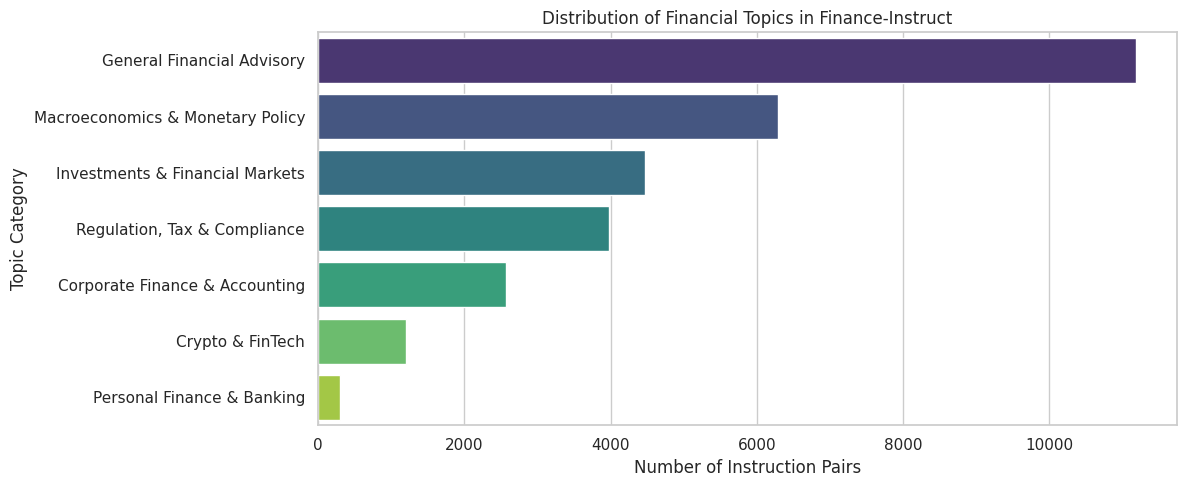

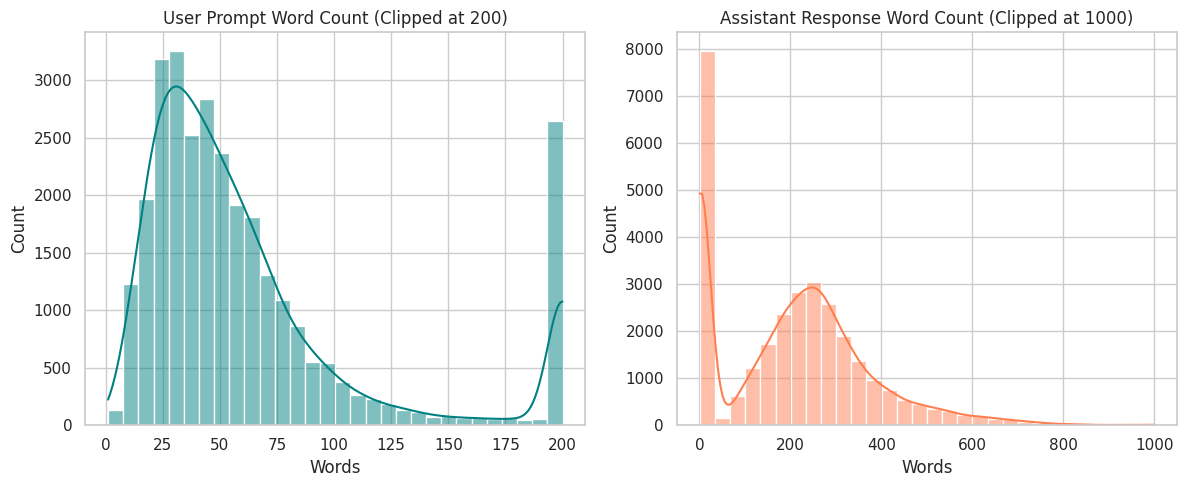

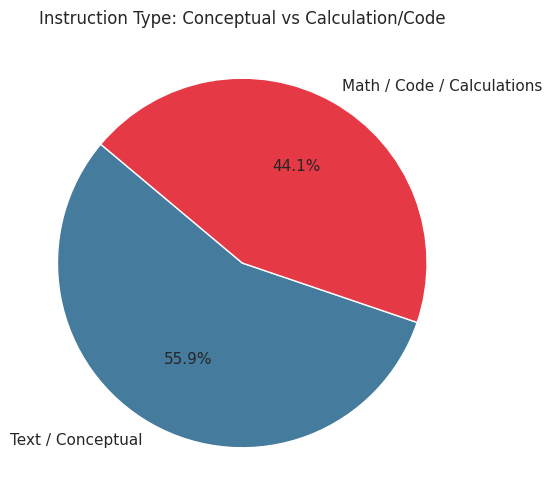

In [6]:
# 1. Financial Categories Distribution
plt.figure(figsize=(12, 5))
cat_counts = df_sample['category'].value_counts()
sns.barplot(x=cat_counts.values, y=cat_counts.index, palette='viridis')
plt.title("Distribution of Financial Topics in Finance-Instruct")
plt.xlabel("Number of Instruction Pairs")
plt.ylabel("Topic Category")
plt.tight_layout()
plt.show()

# 2. Word Count Distribution (User Prompt vs Assistant Response)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df_sample['user_word_count'].clip(upper=200), bins=30, kde=True, color='teal')
plt.title("User Prompt Word Count (Clipped at 200)")
plt.xlabel("Words")

plt.subplot(1, 2, 2)
sns.histplot(df_sample['assistant_word_count'].clip(upper=1000), bins=30, kde=True, color='coral')
plt.title("Assistant Response Word Count (Clipped at 1000)")
plt.xlabel("Words")
plt.tight_layout()
plt.show()

# 3. Calculation & Code Presence
plt.figure(figsize=(6, 6))
code_counts = df_sample['has_calculation_or_code'].value_counts()
plt.pie(code_counts, labels=['Text / Conceptual', 'Math / Code / Calculations'], autopct='%1.1f%%', colors=['#457b9d', '#e63946'], startangle=140)
plt.title("Instruction Type: Conceptual vs Calculation/Code")
plt.show()


---
##  7: Direct Download Link (Optional)


In [7]:
try:
    from google.colab import files
    print("Directly downloading sample CSV to local computer...")
    files.download(SAMPLE_CSV_PATH)
except Exception as e:
    print(f"Direct browser download skipped ({e}). File is stored safely in Google Drive.")


Directly downloading sample CSV to local computer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>